# Mobile Games A/B Testing - Cookie Cats

## Introduction

### Overview

This dataset includes A/B test results of Cookie Cats mobile game to examine what happens when the first gate in the game was moved from level 30 to level 40. When a player installed the game, he or she was randomly assigned to either gate_30 or gate_40.

Dataset includes:
- userid: A unique number that identifies each player.
- version: Whether the player was put in the control group (gate_30 - a gate at level 30) or the group with the moved gate (gate_40 - a gate at level 40).
- sum_gamerounds: the number of game rounds played by the player during the first 14 days after install.
- retention_1: Did the player come back and play 1 day after installing?
- retention_7: Did the player come back and play 7 days after installing?

### Goal of the analysis

The goal of this analysis is to decide if the placement of the progression gate (at level 30 comparing to level 40) significantly impacts player retention and engagement.

Questions to analyse:
1. Does gate placement at level 40 (gate_40) lead to higher 1-day and 7-day retention rates compared to level 30 (gate_30)?
2. Does gate placement affect the total number of game rounds (sum_gamerounds) played in the first 14 days?

### Target metrics

1-day and 7-day retention rate (True or False, measuring days after installation):
- this measures if the users stayed and continued to play the game

Number of game rounds played by a player within the first 14 days after installation:
- this measures how much user was engaged - how many times he/she played the game

### Calculations

#### 1. Data overview

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from cookie_cats_functions import (
    histogram,
    remove_outliers,
    histogram_retention_rates,
    proportion_ci,
    z_test,
    welch_t_test,
    boxplot_gamerounds,
)

In [2]:
df_cats = pd.read_csv("cookie_cats.csv")
df_cats.head(5)

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


In [3]:
print(f"Dataframe shape: {df_cats.shape}")
print(f"\nMissing values:\n{df_cats.isna().sum()}")
print(f"\nDuplicated entries: {df_cats.duplicated().sum()}")

Dataframe shape: (90189, 5)

Missing values:
userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64

Duplicated entries: 0


In [4]:
print(f"Number of users: {df_cats['userid'].nunique()}")
print(f"Number of versions: {df_cats['version'].nunique()}")

Number of users: 90189
Number of versions: 2


In [5]:
df_cats["sum_gamerounds"].agg(["count", "median", "mean", "std", "max"])

count     90189.000000
median       16.000000
mean         51.872457
std         195.050858
max       49854.000000
Name: sum_gamerounds, dtype: float64

In [6]:
df_cats.groupby("version")["sum_gamerounds"].agg(
    ["count", "median", "mean", "std", "min", "max"]
)

,count,median,mean,std,min,max
version,,,,,,
gate_30,44700,17.0,52.456264,256.716423,0,49854
gate_40,45489,16.0,51.298776,103.294416,0,2640


- game rounds data is not normally distributed, right-skewed for both gate versions, because the mean is larger than the median.
- standart deviation for gate_30 is 2.5 times larger than for gate_40, this shows a greater variability in the gate_30 group
- maximum value for gate_30 is much higher than for gate_40 which can indicate outliers

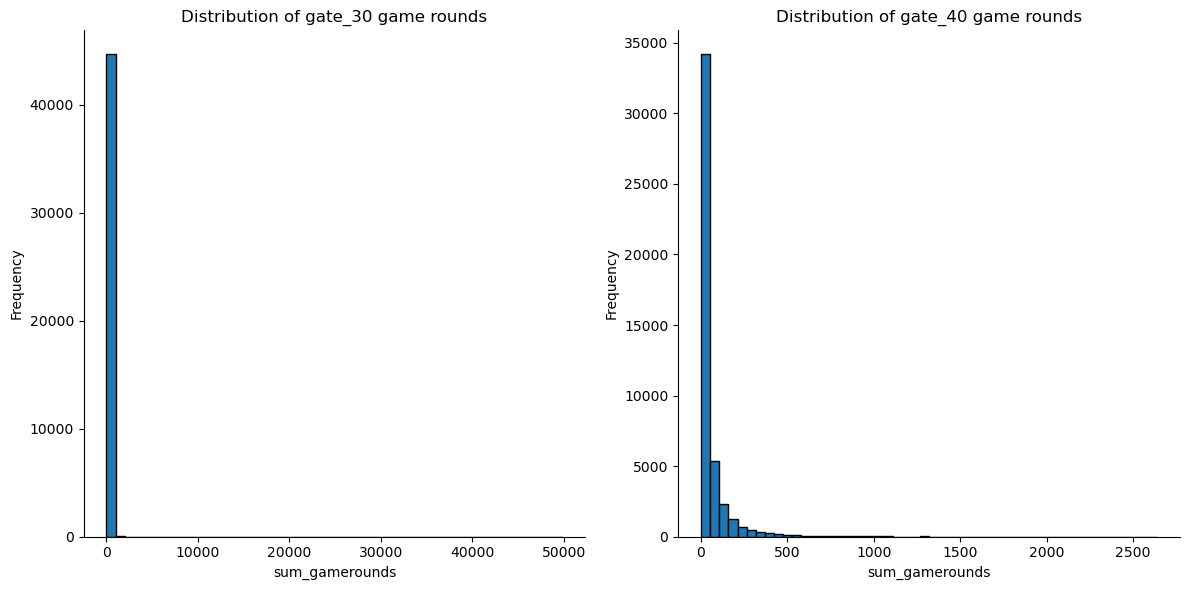

In [7]:
histogram(
    df_cats,
    col="sum_gamerounds",
    group_col="version",
    group_1="gate_30",
    group_2="gate_40",
)

For gate 40 group the distribution is exponential.
For gate 30 group x axis is very wide and most of the values are near zero. This suggest a possibility of outliers.

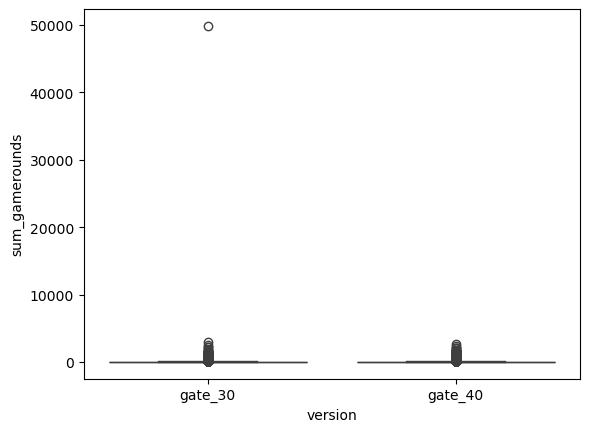

In [8]:
sns.boxplot(data=df_cats, x="version", y="sum_gamerounds")
plt.show()

There is an outlier in the gate_30 group that has to be removed before the statistical analysis.

In [9]:
df_cats_clean = remove_outliers(df_cats, "sum_gamerounds")

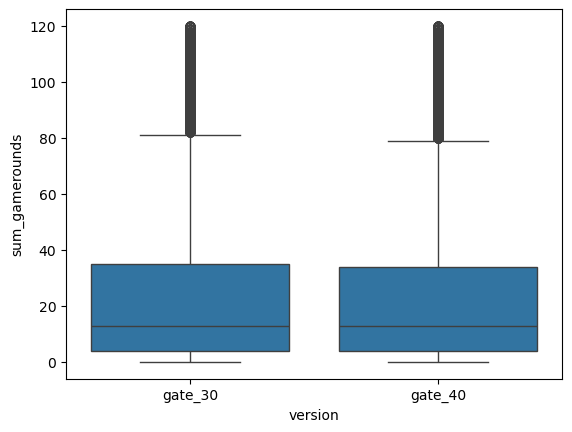

In [10]:
sns.boxplot(data=df_cats_clean, x="version", y="sum_gamerounds")
plt.show()

Now the outliers are removed and the data is prepared for the analysis.

In [11]:
df_cats.groupby("version")["sum_gamerounds"].agg(
    ["count", "median", "mean", "std", "min", "max"]
)

,count,median,mean,std,min,max
version,,,,,,
gate_30,44700,17.0,52.456264,256.716423,0,49854
gate_40,45489,16.0,51.298776,103.294416,0,2640


In [12]:
gate_30_data = df_cats_clean[df_cats_clean["version"] == "gate_30"]["sum_gamerounds"]

statistics_gate_30 = (
    r"$\bf{Gate\ 30}$" + "\n"
    r"$\bf{gameround\ statistics}$" + "\n"
    f"Count: {len(gate_30_data)}\n"
    f"Median: {gate_30_data.median():.2f}\n"
    f"Mean: {gate_30_data.mean():.2f}\n"
    f"Std: {gate_30_data.std():.2f}\n"
    f"Min: {gate_30_data.min():.0f}\n"
    f"Max: {gate_30_data.max():.0f}"
)

In [13]:
gate_40_data = df_cats_clean[df_cats_clean["version"] == "gate_40"]["sum_gamerounds"]

statistics_gate_40 = (
    r"$\bf{Gate\ 40}$" + "\n"
    r"$\bf{gameround\ statistics}$" + "\n"
    f"Count: {len(gate_40_data)}\n"
    f"Median: {gate_40_data.median():.2f}\n"
    f"Mean: {gate_40_data.mean():.2f}\n"
    f"Std: {gate_40_data.std():.2f}\n"
    f"Min: {gate_40_data.min():.0f}\n"
    f"Max: {gate_40_data.max():.0f}"
)

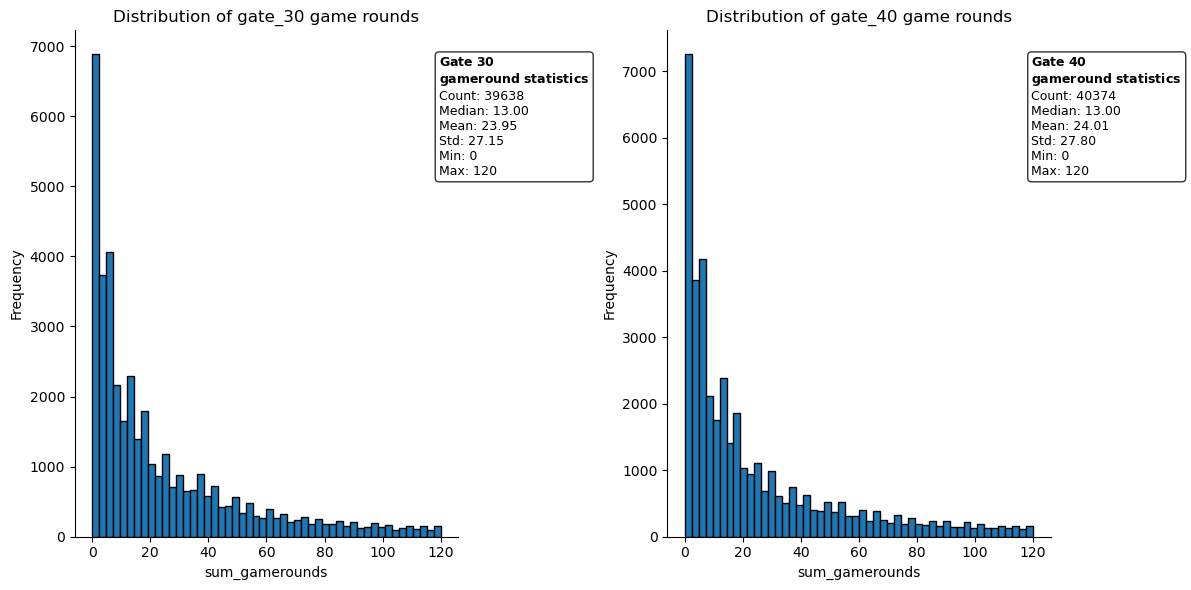

In [14]:
histogram(
    df_cats_clean,
    col="sum_gamerounds",
    group_col="version",
    group_1="gate_30",
    group_2="gate_40",
    text_group1=statistics_gate_30,
    text_group2=statistics_gate_40,
)

- The distribution of gamerounds is exponential
- Group sizes are similar, distributions (standard deviations) are similar.
- Mean values are similar, max values are the same.

In [15]:
total_users = df_cats_clean["userid"].count()

In [16]:
not_active_users = df_cats_clean[df_cats_clean["sum_gamerounds"] == 0]["userid"].count()
not_active_users_perc = not_active_users / total_users * 100

In [17]:
df_cats_clean

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
3,483,gate_40,1,False,False
6,1066,gate_30,0,False,False
7,1444,gate_40,2,False,False
...,...,...,...,...,...
90184,9999441,gate_40,97,True,False
90185,9999479,gate_40,30,False,False
90186,9999710,gate_30,28,True,False
90187,9999768,gate_40,51,True,False


In [18]:
results = {}

for version in ["gate_30", "gate_40"]:
    group = df_cats_clean[df_cats_clean["version"] == version]
    total = len(group)

    counts = {
        "not_active": (group["sum_gamerounds"] == 0).sum(),
        "retention1": group["retention_1"].sum(),
        "retention7": group["retention_7"].sum(),
    }

    percentages = {k: v / total * 100 for k, v in counts.items()}
    ci = [proportion_ci(v, total) * 100 for v in counts.values()]

    results[version] = {
        "counts": counts,
        "percentages": percentages,
        "ci": ci,
        "total": total,
    }

In [19]:
not_active_30 = results["gate_30"]["percentages"]["not_active"]
retention1_30 = results["gate_30"]["percentages"]["retention1"]
retention7_30 = results["gate_30"]["percentages"]["retention7"]

not_active_40 = results["gate_40"]["percentages"]["not_active"]
retention1_40 = results["gate_40"]["percentages"]["retention1"]
retention7_40 = results["gate_40"]["percentages"]["retention7"]

ci_30 = results["gate_30"]["ci"]
ci_40 = results["gate_40"]["ci"]

In [20]:
categories = ["Not active", "1-day retention", "7-day retention"]
gate_30_values = [not_active_30, retention1_30, retention7_30]
gate_40_values = [not_active_40, retention1_40, retention7_40]

In [22]:
print(f"Not active users: {not_active_users}")
print(f"Not active user percent: {not_active_users_perc}%")

Not active users: 3994
Not active user percent: 4.991751237314403%


In [23]:
df_retention = df_cats_clean[["retention_1", "retention_7"]].mean() * 100
print(f"1-day retention ratio: {round(df_retention[0],2)}%")
print(f"7-days retention ratio: {round(df_retention[1],2)}%")

1-day retention ratio: 38.62%
7-days retention ratio: 11.39%


- 3994 users installed the game but never played it. It is 4.99% of total users.
- number of active users decrease as the game progresses
- most users play actively in the earliest game rounds

In [24]:
df_cats_clean.groupby(["version", "retention_1"])["sum_gamerounds"].agg(
    ["count", "median", "mean", "std", "max"]
)

count  median       mean        std  max
version retention_1                                          
gate_30 False        24215     6.0  12.642660  17.491398  120
        True         15423    35.0  41.690786  29.983310  120
gate_40 False        24896     6.0  12.655165  17.972346  120
        True         15478    34.0  42.280656  30.908286  120

In [25]:
df_cats_clean.groupby(["version", "retention_7"])["sum_gamerounds"].agg(
    ["count", "median", "mean", "std", "max"]
)

count  median       mean        std  max
version retention_7                                          
gate_30 False        34956    11.0  19.681113  23.304905  120
        True          4682    53.0  55.780863  32.212640  120
gate_40 False        35941    10.0  19.889541  23.958521  120
        True          4433    55.0  57.440334  33.618387  120

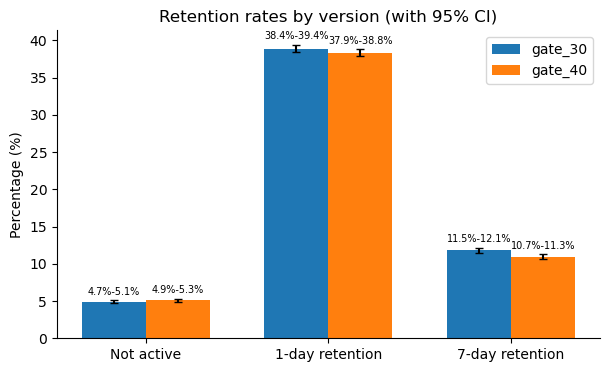

In [21]:
histogram_retention_rates(
    categories=categories,
    gate_30_values=gate_30_values,
    gate_40_values=gate_40_values,
    ci_30=ci_30,
    ci_40=ci_40,
)

Retention rates in the group gate_30 and group gate_40 look similar. Statistical tests are needed to see the statistically significant differences.

#### 2. Statistical tests

#### 2.1 Retention rate

- H₀: there is no statistically significant difference between retention rate for gate_30 and gate_40 groups
- H₁: there is a statistically significant difference between retention rate for gate_30 and gate_40 groups

Retention data is binary, so the distribution is binomial. Since the sample size is large, I will use proportions z-test.

In [26]:
gate_30 = df_cats_clean[df_cats_clean["version"] == "gate_30"]
gate_40 = df_cats_clean[df_cats_clean["version"] == "gate_40"]

total_30 = len(gate_30)
total_40 = len(gate_40)

In [27]:
z_result_1day = z_test(df_cats_clean, "version", "gate_30", "gate_40", "retention_1")
z_result_7day = z_test(df_cats_clean, "version", "gate_30", "gate_40", "retention_7")

z_test_text = (
    r"$\bf{z-test\ gate\ comparison}$" + "\n"
    f"1-day retention:\n"
    f"  p-value: {z_result_1day['p_value']:.4f}\n"
    f"  Cohen's h: {z_result_1day['cohens_h']:.3f}\n"
    f"  Result: {'Significant' if z_result_1day['significant'] else 'Not significant'}\n\n"
    f"7-day retention:\n"
    f"  p-value: {z_result_7day['p_value']:.4f}\n"
    f"  Cohen's h: {z_result_7day['cohens_h']:.3f}\n"
    f"  Result: {'Significant' if z_result_7day['significant'] else 'Not significant'}"
)

stats_text_30 = (
    r"$\bf{Gate\ 40\ statistics}$" + "\n"
    f"Not active: {not_active_30:.1f}%\n"
    f"1-day retention: {retention1_30:.1f}%\n"
    f"7-day retention: {retention7_30:.1f}%\n"
    f"Total users: {total_30}"
)

stats_text_40 = (
    r"$\bf{Gate\ 40\ statistics}$" + "\n"
    f"Not active: {not_active_40:.1f}%\n"
    f"1-day retention: {retention1_40:.1f}%\n"
    f"7-day retention: {retention7_40:.1f}%\n"
    f"Total users: {total_40}"
)

In [28]:
retention1_30_count = results["gate_30"]["counts"]["retention1"]
retention7_30_count = results["gate_30"]["counts"]["retention7"]

retention1_40_count = results["gate_40"]["counts"]["retention1"]
retention7_40_count = results["gate_40"]["counts"]["retention7"]

In [29]:
ci_30 = [
    proportion_ci(retention1_30_count, total_30) * 100,
    proportion_ci(retention7_30_count, total_30) * 100,
]
ci_40 = [
    proportion_ci(retention1_40_count, total_40) * 100,
    proportion_ci(retention7_40_count, total_40) * 100,
]

In [30]:
categories = ["1-day retention", "7-day retention"]
gate_30_values = [retention1_30, retention7_30]
gate_40_values = [retention1_40, retention7_40]

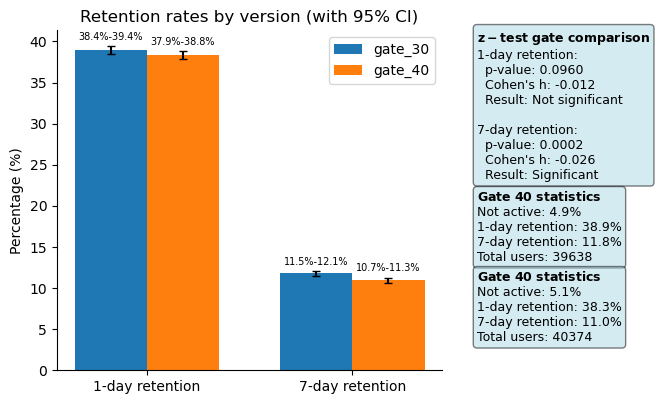

In [31]:
histogram_retention_rates(
    categories=categories,
    gate_30_values=gate_30_values,
    gate_40_values=gate_40_values,
    ci_30=ci_30,
    ci_40=ci_40,
    z_test_text=z_test_text,
    stats_text_30=stats_text_30,
    stats_text_40=stats_text_40,
)

- There is no significant difference in retention rates 7 days after installing the app when the gate is put on 30th level comparing to 40th. The effect size is small.
- The confidence intervals are narrow due to large sample size, which shows that we can estimate population parameters with high precision.

#### 2.2 Game rounds

- H₀: there is no statistically significant difference between game rounds number for gate_30 and gate_40 groups
- H₀: there is a statistically significant difference between game rounds number for gate_30 and gate_40 groups

The outliers were removed previously. The distribution is exponential (not normal).

Variance homogeneity can be tested using Levene test:
- H₀: variances are homogeneous.
- H₁: variances are not homogeneous.

In [32]:
gate_30_gamerounds = df_cats_clean[df_cats_clean["version"] == "gate_30"][
    "sum_gamerounds"
]
gate_40_gamerounds = df_cats_clean[df_cats_clean["version"] == "gate_40"][
    "sum_gamerounds"
]

In [33]:
statistic, p_value = stats.levene(gate_30_gamerounds, gate_40_gamerounds)
print(f"Variances are {'homogenous' if p_value > 0.05 else 'not homogenous'}.")

Variances are homogenous.


For statistical analysis Welch's t-test will be used, since the sample size in each group is large (above 45 000 samples per group). This is used instead of Student's t-test because even though the variances are homogenous, Welch's t-test is more robust, at high sample size gives the same results as Student's t-test and is a standard practice.

In [34]:
welch_t_test_results = welch_t_test(gate_30_gamerounds, gate_40_gamerounds)

In [35]:
welch_t_test_text = (
    r"$\bf{Welch\ t-test\ gate\ comparison}$" + "\n"
    f"t-statistic: {welch_t_test_results['t_statistic']:.4f}\n"
    f"p-value: {welch_t_test_results['p_value']:.4f}\n"
    f"Mean difference: {welch_t_test_results['mean_difference']:.4f}\n"
    f"Cohen's d: {welch_t_test_results['cohens_d']:.3f}\n"
    f"Result: {'Significant' if welch_t_test_results['significant'] else 'Not significant'}"
)

In [36]:
data = [
    df_cats_clean[df_cats_clean["version"] == "gate_30"]["sum_gamerounds"],
    df_cats_clean[df_cats_clean["version"] == "gate_40"]["sum_gamerounds"],
]

In [37]:
labels = ["gate_30", "gate_40"]

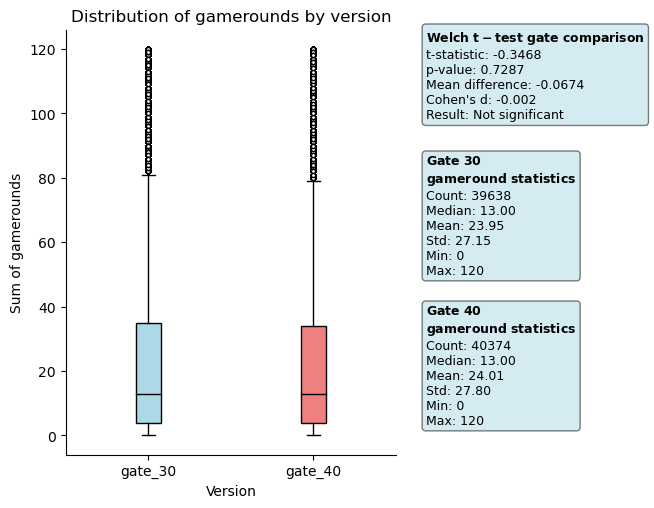

In [38]:
boxplot_gamerounds(
    data=data,
    labels=labels,
    welch_t_test_text=welch_t_test_text,
    statistics_gate_30=statistics_gate_30,
    statistics_gate_40=statistics_gate_40,
)

Looking at the p-value (p > 0.05), small effect size (-0.002), small t-statistic, we see that there is no significant difference in gamerounds played comparing gate_30 group and gate_40 group.

### Decision

There is no significant difference in gamerounds played or retention rates when comparing gate 30 and gate 40 game versions.

### Conclusions
Dataset about a mobile game Cookie Cats was analyzed. This dataset included:
- 90189 users
- 2 game versions (first gate either at level 30 or level 40)
- retention rate after 1 day
- retention rate after 7 days
- game rounds played

There were no significant differences in retention rates or the game rounds played when the gate is put on 30th level comparing to 40th.